## Dataset Preparation

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd
import json

# Load the data from JSON
with open('/content/drive/MyDrive/ASD Level/Metadata/data.json', 'r') as f:
    data_json = json.load(f)

# Convert the 'TCImages' part of the JSON to a DataFrame
df = pd.DataFrame(data_json['TSImages'])
df = df.sort_values('ParticipantID').reset_index(drop = True)
df

,File,ParticipantID,Age,Gender,CARS
0,TS126_01.png,1,7.0,M,32.5
1,TS127_01.png,1,7.0,M,32.5
2,TS128_01.png,1,7.0,M,32.5
3,TS129_01.png,1,7.0,M,32.5
4,TS134_01.png,1,7.0,M,32.5
...,...,...,...,...,...
214,TS218_08.png,8,12.3,F,34.5
215,TS120_09.png,9,2.7,M,27.0
216,TS195_09.png,9,2.7,M,27.0
217,TS118_09.png,9,2.7,M,27.0


In [ ]:
# Add the 'Label' column based on the CARS value
df['Label'] = df['CARS'].apply(lambda x: 0 if x < 30 else 1)

df.head()

In [ ]:
# # Perform train-test split (30% test data)
# from sklearn.model_selection import train_test_split
# train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['Label'])

# print("Train set size:", len(train_df))
# print("Test set size:", len(test_df))

In [ ]:
from sklearn.model_selection import train_test_split

# Separate the dataset into the two classes
df_class_0 = df[df['Label'] == 0]
df_class_1 = df[df['Label'] == 1]

# Allocate 10 samples from class 0 to the test set
test_class_0, train_class_0 = train_test_split(df_class_0, test_size=len(df_class_0) - 10, random_state=42, stratify=df_class_0['Label'])

# Allocate 33 samples from class 1 to the test set
test_class_1, train_class_1 = train_test_split(df_class_1, test_size=len(df_class_1) - 33, random_state=42, stratify=df_class_1['Label'])

# Combine the test sets
test_df = pd.concat([test_class_0, test_class_1])

# Combine the remaining samples to form the training set
train_df = pd.concat([train_class_0, train_class_1])

# Shuffle the train and test sets to ensure random distribution
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Train set size:", len(train_df))
print("Class distribution in train set:")
print(train_df['Label'].value_counts())

print("Test set size:", len(test_df))
print("Class distribution in test set:")
print(test_df['Label'].value_counts())


## RGB Dataset

In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('RGB')
        label = self.dataframe.iloc[idx, -1]  # Assuming 'Label' is the last column

        if self.transform:
            image = self.transform(image)

        return image, label

# Define the image directory and transformations
img_dir = '/content/drive/MyDrive/ASD Level/Images/TSImages'
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 100x100 pixels
    transforms.ToTensor()  # Convert images to PyTorch tensors
])

# Create the training and testing datasets
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, transform=transform)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, transform=transform)

# Create DataLoaders for training and testing sets
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Example: Iterate over the training DataLoader
for images, labels in train_dataloader:
    print("Train batch:")
    print(images.shape)  # Should print torch.Size([32, 3, 100, 100]) for a batch of 32 images
    print(labels)        # Labels for the batch
    break  # Just to test a single batch

# Example: Iterate over the testing DataLoader
for images, labels in test_dataloader:
    print("Test batch:")
    print(images.shape)  # Should print torch.Size([32, 3, 100, 100]) for a batch of 32 images
    print(labels)        # Labels for the batch
    break  # Just to test a single batch


In [ ]:
pd.DataFrame([all_labels, all_preds])

## Resnet 50

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained ResNet50 model
model = models.resnet50(pretrained=True)

# Freeze the early layers (optional)
for param in model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate on the test set
model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = model(inputs)

        # Get predictions
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

## DenseNet121

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained DenseNet121 model
model = models.densenet121(pretrained=True)

# Freeze the early layers (optional)
for param in model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate on the test set
model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = model(inputs)

        # Get predictions
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")



## ViT

In [ ]:
pip install -q torchvision

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained Vision Transformer (ViT-B/16) model
model = models.vit_b_16(pretrained=True)

# Freeze the early layers (optional)
for param in model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = model.heads.head.in_features
model.heads.head = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.heads.head.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate on the test set
model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = model(inputs)

        # Get predictions
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

## Greyscale Dataset

In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('L')  # Convert image to grayscale
        label = self.dataframe.iloc[idx, -1]  # Assuming 'Label' is the last column

        if self.transform:
            image = self.transform(image)

        return image, label

# Define the image directory and transformations
img_dir = '/content/drive/MyDrive/ASD Level/Images/TSImages'
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 224x224 pixels (to match ViT input size)
    transforms.ToTensor()  # Convert images to PyTorch tensors
])


# Create the training and testing datasets
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, transform=transform)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, transform=transform)

# Create DataLoaders for training and testing sets
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Example: Iterate over the training DataLoader
for images, labels in train_dataloader:
    print("Train batch:")
    print(images.shape)  # Should print torch.Size([32, 1, 224, 224]) for a batch of 32 grayscale images
    print(labels)        # Labels for the batch
    break  # Just to test a single batch

# Example: Iterate over the testing DataLoader
for images, labels in test_dataloader:
    print("Test batch:")
    print(images.shape)  # Should print torch.Size([32, 1, 224, 224]) for a batch of 32 grayscale images
    print(labels)        # Labels for the batch
    break  # Just to test a single batch


## Greyscale Resnet18

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained ResNet18 model
model = models.resnet18(pretrained=True)

# Modify the first convolutional layer to accept 1-channel (grayscale) input instead of 3-channel (RGB) input
model.conv1 = nn.Conv2d(1, model.conv1.out_channels, kernel_size=model.conv1.kernel_size, stride=model.conv1.stride, padding=model.conv1.padding, bias=False)

# Freeze the early layers (optional)
for param in model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate on the test set
model.eval()  # Set model to evaluation mode
all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = model(inputs)

        # Get predictions
        _, preds = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

## Greyscale ViT

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import ViTForImageClassification, ViTFeatureExtractor
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import os

# Load the pretrained ViT model from Hugging Face
model = ViTForImageClassification.from_pretrained('google/vit-base-patch16-224-in21k', num_labels=2)

# Load the feature extractor for ViT
feature_extractor = ViTFeatureExtractor.from_pretrained('google/vit-base-patch16-224-in21k')

# Modify dataset class to handle grayscale images and use the feature extractor
class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, feature_extractor):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.feature_extractor = feature_extractor

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('L')  # Convert image to grayscale
        image = image.convert('RGB')  # Convert grayscale to RGB by stacking

        # Apply the feature extractor (which includes resizing and normalization)
        image = self.feature_extractor(images=image, return_tensors="pt")['pixel_values'][0]

        label = self.dataframe.iloc[idx, -1]  # Assuming 'Label' is the last column
        return image, label

# Define the image directory
img_dir = '/content/drive/MyDrive/ASD Level/Images/TSImages'

# Create the datasets and dataloaders
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, feature_extractor=feature_extractor)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, feature_extractor=feature_extractor)

train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Move the model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(pixel_values=inputs).logits
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Set the model to evaluation mode
model.eval()

# Initialize lists to store labels and predictions
all_labels = []
all_preds = []

# Disable gradient calculation for evaluation
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass to get outputs
        outputs = model(pixel_values=inputs).logits

        # Get the predicted class (0 or 1)
        _, preds = torch.max(outputs, 1)

        # Store the true labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Calculate evaluation metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

# Print the results
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")


## Autoencoders

In [ ]:
pip install -q torchmetrics

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchmetrics.functional import structural_similarity_index_measure as ssim

class SimpleAutoencoder(nn.Module):
    def __init__(self):
        super(SimpleAutoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),  # [batch, 32, 112, 112]
            nn.ReLU(True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # [batch, 64, 56, 56]
            nn.ReLU(True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1), # [batch, 128, 28, 28]
            nn.ReLU(True)
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1), # [batch, 64, 56, 56]
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), # [batch, 32, 112, 112]
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),  # [batch, 1, 224, 224]
            nn.Sigmoid()  # Sigmoid to keep the pixel values between 0 and 1
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Initialize the model
autoencoder = SimpleAutoencoder().cuda()

# Define optimizer
optimizer = optim.Adam(autoencoder.parameters(), lr=0.0001)

# L1 regularization weight
l1_lambda = 0.0001


In [ ]:
# Training the autoencoder with SSIM and L1 Loss
num_epochs = 50  # Increase the number of epochs

for epoch in range(num_epochs):
    autoencoder.train()
    running_loss = 0.0
    for data in train_dataloader:
        images, _ = data
        images = images.cuda()  # Move to GPU if available

        # Forward pass
        outputs = autoencoder(images)

        # Calculate SSIM loss
        ssim_loss = 1 - ssim(outputs, images, data_range=1.0)

        # Calculate L1 loss
        l1_loss = torch.abs(outputs - images).mean()

        # Combine SSIM and L1 loss
        loss = ssim_loss + l1_lambda * l1_loss

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_dataloader):.4f}')

print("Training Complete.")


In [ ]:
import matplotlib.pyplot as plt

# Function to display images
def imshow(img):
    img = img.cpu().numpy().transpose(1, 2, 0)  # Move to CPU and rearrange dimensions
    plt.imshow(img, cmap='gray')
    plt.axis('off')

# Visualize a few samples
autoencoder.eval()
with torch.no_grad():
    dataiter = iter(test_dataloader)
    images, _ = next(dataiter)
    images = images.cuda()

    outputs = autoencoder(images)

    # Plotting the original and reconstructed images
    fig, axes = plt.subplots(2, 6, figsize=(15, 5))
    for i in range(6):
        # Original images
        axes[0, i].imshow(images[i].cpu().squeeze(), cmap='gray')
        axes[0, i].axis('off')
        axes[0, i].set_title('Original')

        # Reconstructed images
        axes[1, i].imshow(outputs[i].cpu().squeeze(), cmap='gray')
        axes[1, i].axis('off')
        axes[1, i].set_title('Reconstructed')

    plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Visualize some of the images in the dataset
def visualize_data(dataframe, img_dir, n_samples=6):
    fig, axes = plt.subplots(1, n_samples, figsize=(15, 5))
    for i in range(n_samples):
        img_path = os.path.join(img_dir, dataframe.iloc[i, 0])
        img = Image.open(img_path).convert('L')
        axes[i].imshow(np.array(img), cmap='gray')
        axes[i].axis('off')
    plt.show()

# Example usage
visualize_data(train_df, img_dir)


## CNN

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Define the layers of the CNN
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.fc2 = nn.Linear(512, 2)  # Assuming binary classification (ASD vs TD)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # Apply convolution -> ReLU -> Pooling
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)  # Flatten the tensor
        x = F.relu(self.fc1(x))  # Fully connected layer -> ReLU
        x = self.dropout(x)
        x = self.fc2(x)  # Final output layer
        return x

# Instantiate the model
model = CNN().cuda()

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


In [ ]:
num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for data in train_dataloader:
        images, labels = data
        images, labels = images.cuda(), labels.cuda()

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Calculate running loss and accuracy
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}, Accuracy: {100 * correct / total:.2f}%")


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.cuda(), labels.cuda()
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")


## Three ASD Levels

In [6]:
# Add the 'Label' column based on the CARS value with 3 levels:
# 1: Non-Autistic
# 2: Mild to Moderate Autism
# 3: Severe Autism
df['Label'] = df['CARS'].apply(lambda x: 0 if x < 30 else (1 if 30 <= x <= 36.5 else 2))

# Display the first few rows of the DataFrame to verify
df.head()


,File,ParticipantID,Age,Gender,CARS,Label
0,TS126_01.png,1,7.0,M,32.5,1
1,TS127_01.png,1,7.0,M,32.5,1
2,TS128_01.png,1,7.0,M,32.5,1
3,TS129_01.png,1,7.0,M,32.5,1
4,TS134_01.png,1,7.0,M,32.5,1


In [7]:
print(df[['Label']].value_counts())

Label
0        98
1        97
2        24
Name: count, dtype: int64


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

# Separate the dataset into the three classes
df_label_1 = df[df['Label'] == 0]
df_label_2 = df[df['Label'] == 1]
df_label_3 = df[df['Label'] == 2]

# Split Label 1
test_label_1, train_label_1 = train_test_split(df_label_1, test_size=len(df_label_1) - 18, random_state=42, stratify=df_label_1['Label'])

# Split Label 2
test_label_2, train_label_2 = train_test_split(df_label_2, test_size=len(df_label_2) - 17, random_state=42, stratify=df_label_2['Label'])

# Split Label 3
test_label_3, train_label_3 = train_test_split(df_label_3, test_size=len(df_label_3) - 4, random_state=42, stratify=df_label_3['Label'])

# Combine the test sets
test_df = pd.concat([test_label_1, test_label_2, test_label_3])

# Combine the remaining samples to form the training set
train_df = pd.concat([train_label_1, train_label_2, train_label_3])

# Oversample Label 3 in the training set to 60 samples
df_label_3_oversampled = resample(train_label_3,
                                  replace=True,    # Sample with replacement
                                  n_samples=60,    # Number of samples in the oversampled class
                                  random_state=42) # Reproducibility

# Combine the oversampled Label 3 with the rest of the training data
train_df = pd.concat([train_df[train_df['Label'] != 3], df_label_3_oversampled])

# Shuffle the train_df to mix the data well
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Verify the splits and oversampling
print("Training set label distribution:")
print(train_df['Label'].value_counts())

print("\nTest set label distribution:")
print(test_df['Label'].value_counts())


Training set label distribution:
Label
0    80
1    80
2    80
Name: count, dtype: int64

Test set label distribution:
Label
0    18
1    17
2     4
Name: count, dtype: int64


In [9]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('L')  # Convert image to grayscale
        label = self.dataframe.iloc[idx, -1]  # Assuming 'Label' is the last column

        if self.transform:
            image = self.transform(image)

        return image, label

# Define the image directory and transformations
img_dir = '/content/drive/MyDrive/ASD Level/Images/TSImages'
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 224x224 pixels (to match ViT input size)
    transforms.ToTensor()  # Convert images to PyTorch tensors
])


# Create the training and testing datasets
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, transform=transform)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, transform=transform)

# Create DataLoaders for training and testing sets
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Example: Iterate over the training DataLoader
for images, labels in train_dataloader:
    print("Train batch:")
    print(images.shape)  # Should print torch.Size([32, 1, 224, 224]) for a batch of 32 grayscale images
    print(labels)        # Labels for the batch
    break  # Just to test a single batch

# Example: Iterate over the testing DataLoader
for images, labels in test_dataloader:
    print("Test batch:")
    print(images.shape)  # Should print torch.Size([32, 1, 224, 224]) for a batch of 32 grayscale images
    print(labels)        # Labels for the batch
    break  # Just to test a single batch



Train batch:
torch.Size([32, 1, 224, 224])
tensor([1, 0, 0, 1, 2, 1, 2, 2, 0, 0, 2, 0, 1, 2, 1, 1, 1, 0, 0, 2, 2, 0, 2, 2,
        0, 1, 2, 0, 1, 0, 1, 0])
Test batch:
torch.Size([32, 1, 224, 224])
tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1])


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Define the layers of the CNN
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)  # Updated to 1 channel for grayscale input
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.fc2 = nn.Linear(512, 3)  # Updated to 3 for three classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # Apply convolution -> ReLU -> Pooling
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)  # Flatten the tensor
        x = F.relu(self.fc1(x))  # Fully connected layer -> ReLU
        x = self.dropout(x)
        x = self.fc2(x)  # Final output layer
        return x

# Instantiate the model and move it to the appropriate device
model = CNN().to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)  # Move inputs and labels to the device

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


Epoch [1/100], Loss: 1.3808
Epoch [2/100], Loss: 1.1011


Test Accuracy: 0.7674

Class 0 - Precision: 0.0000, Recall: 0.0000, F1 Score: 0.0000

Class 1 - Precision: 0.7674, Recall: 1.0000, F1 Score: 0.8684


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


ValueError: The number of FixedLocator locations (2), usually from a call to set_ticks, does not match the number of labels (3).

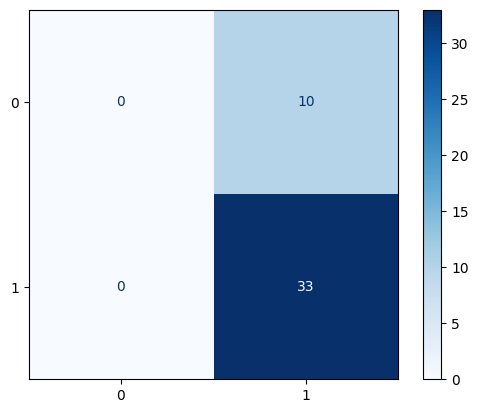

In [97]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import torch
import numpy as np
import matplotlib.pyplot as plt

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []

# Disable gradient computation for evaluation
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)

        # Store labels and predictions
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

# Calculate overall metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='macro')  # Macro average for multi-class
recall = recall_score(all_labels, all_predictions, average='macro')        # Macro average for multi-class
f1 = f1_score(all_labels, all_predictions, average='macro')                # Macro average for multi-class

# Print the overall metrics
print(f"Test Accuracy: {accuracy:.4f}")

# Calculate and print class-specific metrics
class_precision = precision_score(all_labels, all_predictions, average=None)  # Precision for each class
class_recall = recall_score(all_labels, all_predictions, average=None)        # Recall for each class
class_f1 = f1_score(all_labels, all_predictions, average=None)                # F1 Score for each class

for i, (p, r, f) in enumerate(zip(class_precision, class_recall, class_f1)):
    print(f"\nClass {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1 Score: {f:.4f}")

# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1, 2])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()
